In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm #Import for the OLS regression

#Imports for The Workbook

In [2]:
Housing_df = pd.read_excel('/Users/Keyan/Downloads/HousingPermitsandPopulationGrowth.xlsx') #Imports the data
pd.set_option('display.max_columns', None) #This is used to show all columns
Housing_df.head() #This displays a few of the rows based on what you put in the parentheses, if you don't put a number, it displays 5.

,County_State_Name,Year,Total_Population,Foreign_Born_Population,Foreign_Born_Pct,Change_In_Foreign_Born_Share,HS_Grad_or_Higher,Bach_Degree_or_Higher,Total_Permits,Single_Family_Permits,Tot_Multifamily_Permits,2_Unit_Permits,3_or_4_Unit_Permits,5_or_More_Unit_Permits,Median_House_Value,Total_Paying_30_to_34.9_Pct,Total_Paying_Over_35_Pct,Median_Rent,Housing_Units_Per_1000,Occupied_Housing_Units,Growth_In_Occupied_Housing_Units,Corresponding_Growth_In_Occupied_Housing_Units,Owner_Occupied,Median_Household_Income,Median_Age_Years,Pct_Age_65_or_above,Working_Age_Population,Total_Number_Employed,Number_In_Poverty,White_Population,Black_Population,Asian_Population,Hispanic_Population,Land_Area_Sq_Miles,Total_Permits_per_100,Total_Permits_per_1000,Single_Family_Permits_per_100,Single_Family_Permits_per_1000,Total_Multifamily_Permits_per_100,Total_Multifamily_Permits_per_1000,2_Unit_Permits_per_1000,3_or_4_Unit_Permits_per_1000,5_or_More_Unit_Permits_per_100,5_or_More_Unit_Permits_per_1000,3_or_More_Unit_Permits_per_1000,Homeownership_Rate,Employment_Population_Ratio,Poverty_Rate,White_Pct,Black_Pct,Asian_Pct,Hispanic_Pct,Rent_Burden_Over_30_Pct,Population_Density,Previous_Population,Population_Growth,Corresponding_Population_Growth,Population_Growth_Rate,Lag_Total_Permits_per_1000,Lag_Single_Family_Permits_per_1000,Lag_3_or_More_Unit_Permits_per_1000,Lag_Total_Multifamily_Permits_per_1000,Lag_Median_House_Value,Lag_Median_Rent,Lag_Median_Household_Income,Total_Permits_Growth_Rate,Single_Family_Permits_Growth_Rate,Median_House_Value_Growth_Rate,Median_Rent_Growth_Rate,Median_Household_Income_Growth_Rate
0,Abbeville County: South Carolina,2010,25643,369,1.438989,0.022896,76.8,15.3,19.0,19.0,0.0,0.0,0.0,0.0,85900.0,216.0,947.0,539.0,385.095348,9875,NaN,-0.648101,7642.0,33143.0,41.1,16.0,20314.0,9993.0,5084.0,17741.0,7281.0,49.0,268.0,491.193,0.074094,0.74094,0.074094,0.74094,0.0,0.0,0.0,0.0,0.0,0.0,0.0,77.38734,49.19268,19.82607,69.18457,28.39371,0.19109,1.04512,52.08240,52.205549,NaN,NaN,-0.499162,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Abbeville County: South Carolina,2011,25515,373,1.461885,-0.315629,77.1,13.9,32.0,32.0,0.0,0.0,0.0,0.0,89100.0,171.0,912.0,557.0,384.518910,9811,-0.648101,0.682907,7638.0,34670.0,41.9,16.3,20268.0,9814.0,4842.0,17630.0,7493.0,22.0,88.0,491.193,0.125416,1.25416,0.125416,1.25416,0.0,0.0,0.0,0.0,0.0,0.0,0.0,77.85139,48.42116,18.97707,69.09661,29.36704,0.08622,0.34490,49.83893,51.944958,25643.0,-0.499162,-0.501666,-0.49916,0.74094,0.74094,0.0,0.0,85900.0,539.0,33143.0,69.266067,69.266067,3.72526,3.33952,4.60731
2,Abbeville County: South Carolina,2012,25387,291,1.146256,-0.127748,75.7,12.5,23.0,23.0,0.0,0.0,0.0,0.0,90300.0,221.0,805.0,593.0,389.096782,9878,0.682907,-0.698522,7675.0,35067.0,42.4,16.9,20266.0,9599.0,5101.0,17523.0,7144.0,15.0,267.0,491.193,0.090598,0.90598,0.090598,0.90598,0.0,0.0,0.0,0.0,0.0,0.0,0.0,77.69791,47.36504,20.09296,69.02352,28.14039,0.05909,1.05172,46.57286,51.684368,25515.0,-0.501666,-0.606610,-0.50167,1.25416,1.25416,0.0,0.0,89100.0,557.0,34670.0,-27.762008,-27.762008,1.34680,6.46320,1.14508
3,Abbeville County: South Carolina,2013,25233,257,1.018508,0.101014,76.8,12.2,28.0,28.0,0.0,0.0,0.0,0.0,91200.0,98.0,910.0,629.0,388.736971,9809,-0.698522,-0.581099,7491.0,35947.0,42.8,17.3,20283.0,9341.0,5272.0,17421.0,7308.0,14.0,144.0,491.193,0.110966,1.10966,0.110966,1.10966,0.0,0.0,0.0,0.0,0.0,0.0,0.0,76.36864,46.05335,20.89327,69.04054,28.96207,0.05548,0.57068,43.48576,51.370846,25387.0,-0.606610,-0.527088,-0.60661,0.90598,0.90598,0.0,0.0,90300.0,593.0,35067.0,22.481732,22.481732,0.99668,6.07083,2.50948
4,Abbeville County: South Carolina,2014,25100,281,1.119522,0.028616,77.7,12.3,41.0,41.0,0.0,0.0,0.0,0.0,89000.0,109.0,934.0,583.0,388.525896,9752,-0.581099,-1.835521,7624.0,35409.0,43.1,17.9,20335.0,9361.0,5618.0,17307.0,7233.0,1.0,139.0,491.193,0.163347,1.63347,0.163347,1.63347,0.0,0.0,0.0,0.0,0.0,0.0,0.0,78.17884,46.03393,22.38247,68.95219,28.81673,0.00398,0.55378,49.01

In [3]:
Housing_df.columns
#Displays all of the columns

Index(['County_State_Name', 'Year', 'Total_Population',
       'Foreign_Born_Population', 'Foreign_Born_Pct',
       'Change_In_Foreign_Born_Share', 'HS_Grad_or_Higher',
       'Bach_Degree_or_Higher', 'Total_Permits', 'Single_Family_Permits',
       'Tot_Multifamily_Permits', '2_Unit_Permits', '3_or_4_Unit_Permits',
       '5_or_More_Unit_Permits', 'Median_House_Value',
       'Total_Paying_30_to_34.9_Pct', 'Total_Paying_Over_35_Pct',
       'Median_Rent', 'Housing_Units_Per_1000', 'Occupied_Housing_Units',
       'Growth_In_Occupied_Housing_Units',
       'Corresponding_Growth_In_Occupied_Housing_Units', 'Owner_Occupied',
       'Median_Household_Income', 'Median_Age_Years', 'Pct_Age_65_or_above',
       'Working_Age_Population', 'Total_Number_Employed', 'Number_In_Poverty',
       'White_Population', 'Black_Population', 'Asian_Population',
       'Hispanic_Population', 'Land_Area_Sq_Miles', 'Total_Permits_per_100',
       'Total_Permits_per_1000', 'Single_Family_Permits_per_100',
  

In [4]:
Housing_df.loc[Housing_df["Year"] == 2020, "Corresponding_Population_Growth"] = np.nan
#This function locates all instances where the year equals 2020 (it uses a double equal sign because one equal sign just assigns things
#while a double checks what the values are, and it assigns 2020 values for corresponding population growth as N/A

#The reason I did this is because population numbers in 2021 are heavily affected by the covid pandemic, and as a result
#the function is bad at modeling county level growth when it's so heavily affected by the pandemic.

#The reason this removes 2020 data and not 2021 data is because 2020 corresponding growth is essentially 2021 population vs 2020 population
#put back to 2020. I made that choice because characteristics in counties within the year 2020 affect population growth between 2020 to 2021
#As a result, 2020 characteristics affect 2021 population growth and subsequently, the easier choice is to just take those population growth
#numbers and run them a year back. Crucially, this gives you 2010 data, but not 2022 data, unless you get population data from 2023, which
#I did, as well as getting data from a couple other comments

Housing_df.head(13) #Shows the first 13 observations, all of which belong to the first county in alphabetical order

,County_State_Name,Year,Total_Population,Foreign_Born_Population,Foreign_Born_Pct,Change_In_Foreign_Born_Share,HS_Grad_or_Higher,Bach_Degree_or_Higher,Total_Permits,Single_Family_Permits,Tot_Multifamily_Permits,2_Unit_Permits,3_or_4_Unit_Permits,5_or_More_Unit_Permits,Median_House_Value,Total_Paying_30_to_34.9_Pct,Total_Paying_Over_35_Pct,Median_Rent,Housing_Units_Per_1000,Occupied_Housing_Units,Growth_In_Occupied_Housing_Units,Corresponding_Growth_In_Occupied_Housing_Units,Owner_Occupied,Median_Household_Income,Median_Age_Years,Pct_Age_65_or_above,Working_Age_Population,Total_Number_Employed,Number_In_Poverty,White_Population,Black_Population,Asian_Population,Hispanic_Population,Land_Area_Sq_Miles,Total_Permits_per_100,Total_Permits_per_1000,Single_Family_Permits_per_100,Single_Family_Permits_per_1000,Total_Multifamily_Permits_per_100,Total_Multifamily_Permits_per_1000,2_Unit_Permits_per_1000,3_or_4_Unit_Permits_per_1000,5_or_More_Unit_Permits_per_100,5_or_More_Unit_Permits_per_1000,3_or_More_Unit_Permits_per_1000,Homeownership_Rate,Employment_Population_Ratio,Poverty_Rate,White_Pct,Black_Pct,Asian_Pct,Hispanic_Pct,Rent_Burden_Over_30_Pct,Population_Density,Previous_Population,Population_Growth,Corresponding_Population_Growth,Population_Growth_Rate,Lag_Total_Permits_per_1000,Lag_Single_Family_Permits_per_1000,Lag_3_or_More_Unit_Permits_per_1000,Lag_Total_Multifamily_Permits_per_1000,Lag_Median_House_Value,Lag_Median_Rent,Lag_Median_Household_Income,Total_Permits_Growth_Rate,Single_Family_Permits_Growth_Rate,Median_House_Value_Growth_Rate,Median_Rent_Growth_Rate,Median_Household_Income_Growth_Rate
0,Abbeville County: South Carolina,2010,25643,369,1.438989,0.022896,76.8,15.3,19.0,19.0,0.0,0.0,0.0,0.0,85900.0,216.0,947.0,539.0,385.095348,9875,NaN,-0.648101,7642.0,33143.0,41.1,16.0,20314.0,9993.0,5084.0,17741.0,7281.0,49.0,268.0,491.193,0.074094,0.74094,0.074094,0.74094,0.000000,0.00000,0.00000,0.0,0.000000,0.00000,0.00000,77.38734,49.19268,19.82607,69.18457,28.39371,0.19109,1.04512,52.08240,52.205549,NaN,NaN,-0.499162,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Abbeville County: South Carolina,2011,25515,373,1.461885,-0.315629,77.1,13.9,32.0,32.0,0.0,0.0,0.0,0.0,89100.0,171.0,912.0,557.0,384.518910,9811,-0.648101,0.682907,7638.0,34670.0,41.9,16.3,20268.0,9814.0,4842.0,17630.0,7493.0,22.0,88.0,491.193,0.125416,1.25416,0.125416,1.25416,0.000000,0.00000,0.00000,0.0,0.000000,0.00000,0.00000,77.85139,48.42116,18.97707,69.09661,29.36704,0.08622,0.34490,49.83893,51.944958,25643.0,-0.499162,-0.501666,-0.49916,0.74094,0.74094,0.00000,0.00000,85900.0,539.0,33143.0,69.266067,69.266067,3.72526,3.33952,4.60731
2,Abbeville County: South Carolina,2012,25387,291,1.146256,-0.127748,75.7,12.5,23.0,23.0,0.0,0.0,0.0,0.0,90300.0,221.0,805.0,593.0,389.096782,9878,0.682907,-0.698522,7675.0,35067.0,42.4,16.9,20266.0,9599.0,5101.0,17523.0,7144.0,15.0,267.0,491.193,0.090598,0.90598,0.090598,0.90598,0.000000,0.00000,0.00000,0.0,0.000000,0.00000,0.00000,77.69791,47.36504,20.09296,69.02352,28.14039,0.05909,1.05172,46.57286,51.684368,25515.0,-0.501666,-0.606610,-0.50167,1.25416,1.25416,0.00000,0.00000,89100.0,557.0,34670.0,-27.762008,-27.762008,1.34680,6.46320,1.14508
3,Abbeville County: South Carolina,2013,25233,257,1.018508,0.101014,76.8,12.2,28.0,28.0,0.0,0.0,0.0,0.0,91200.0,98.0,910.0,629.0,388.736971,9809,-0.698522,-0.581099,7491.0,35947.0,42.8,17.3,20283.0,9341.0,5272.0,17421.0,7308.0,14.0,144.0,491.193,0.110966,1.10966,0.110966,1.10966,0.000000,0.00000,0.00000,0.0,0.000000,0.00000,0.00000,76.36864,46.05335,20.89327,69.04054,28.96207,0.05548,0.57068,43.48576,51.370846,25387.0,-0.606610,-0.527088,-0.60661,0.90598,0.90598,0.00000,0.00000,90300.0,593.0,35067.0,22.481732,22.481732,0.99668,6.07083,2.50948
4,Abbeville County: South Carolina,2014,25100,281,1.119522,0.028616,77.7,12.3,41.0,41.0,0.0,0.0,0.0,0.0,89000.0,109.0,934.0,583.0,388.525896,9752,-0.581099,-1.835521,7624.0,35409.0,43.1,17.9,20335.0,9361.0,5618.0,17307.0,7233.0,1.0,139.0,491.193,

In [5]:
Housing_df = Housing_df[Housing_df["Total_Population"] >= 2500]
Housing_df = Housing_df[Housing_df["Total_Multifamily_Permits_per_1000"] < 20]

print(Housing_df.shape[0])

Housing_df.head()


#The first line gets rid of counties with a population of under 2500 because they tend to be very noisy, while the 2nd one gets rid of 
#counties giving more than 20 multifamily permits per 1000, as it forms a sample of roughly 30 observations which significantly muddy the 
#effects of multifamily permitting on population growth

38990


,County_State_Name,Year,Total_Population,Foreign_Born_Population,Foreign_Born_Pct,Change_In_Foreign_Born_Share,HS_Grad_or_Higher,Bach_Degree_or_Higher,Total_Permits,Single_Family_Permits,Tot_Multifamily_Permits,2_Unit_Permits,3_or_4_Unit_Permits,5_or_More_Unit_Permits,Median_House_Value,Total_Paying_30_to_34.9_Pct,Total_Paying_Over_35_Pct,Median_Rent,Housing_Units_Per_1000,Occupied_Housing_Units,Growth_In_Occupied_Housing_Units,Corresponding_Growth_In_Occupied_Housing_Units,Owner_Occupied,Median_Household_Income,Median_Age_Years,Pct_Age_65_or_above,Working_Age_Population,Total_Number_Employed,Number_In_Poverty,White_Population,Black_Population,Asian_Population,Hispanic_Population,Land_Area_Sq_Miles,Total_Permits_per_100,Total_Permits_per_1000,Single_Family_Permits_per_100,Single_Family_Permits_per_1000,Total_Multifamily_Permits_per_100,Total_Multifamily_Permits_per_1000,2_Unit_Permits_per_1000,3_or_4_Unit_Permits_per_1000,5_or_More_Unit_Permits_per_100,5_or_More_Unit_Permits_per_1000,3_or_More_Unit_Permits_per_1000,Homeownership_Rate,Employment_Population_Ratio,Poverty_Rate,White_Pct,Black_Pct,Asian_Pct,Hispanic_Pct,Rent_Burden_Over_30_Pct,Population_Density,Previous_Population,Population_Growth,Corresponding_Population_Growth,Population_Growth_Rate,Lag_Total_Permits_per_1000,Lag_Single_Family_Permits_per_1000,Lag_3_or_More_Unit_Permits_per_1000,Lag_Total_Multifamily_Permits_per_1000,Lag_Median_House_Value,Lag_Median_Rent,Lag_Median_Household_Income,Total_Permits_Growth_Rate,Single_Family_Permits_Growth_Rate,Median_House_Value_Growth_Rate,Median_Rent_Growth_Rate,Median_Household_Income_Growth_Rate
0,Abbeville County: South Carolina,2010,25643,369,1.438989,0.022896,76.8,15.3,19.0,19.0,0.0,0.0,0.0,0.0,85900.0,216.0,947.0,539.0,385.095348,9875,NaN,-0.648101,7642.0,33143.0,41.1,16.0,20314.0,9993.0,5084.0,17741.0,7281.0,49.0,268.0,491.193,0.074094,0.74094,0.074094,0.74094,0.0,0.0,0.0,0.0,0.0,0.0,0.0,77.38734,49.19268,19.82607,69.18457,28.39371,0.19109,1.04512,52.08240,52.205549,NaN,NaN,-0.499162,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Abbeville County: South Carolina,2011,25515,373,1.461885,-0.315629,77.1,13.9,32.0,32.0,0.0,0.0,0.0,0.0,89100.0,171.0,912.0,557.0,384.518910,9811,-0.648101,0.682907,7638.0,34670.0,41.9,16.3,20268.0,9814.0,4842.0,17630.0,7493.0,22.0,88.0,491.193,0.125416,1.25416,0.125416,1.25416,0.0,0.0,0.0,0.0,0.0,0.0,0.0,77.85139,48.42116,18.97707,69.09661,29.36704,0.08622,0.34490,49.83893,51.944958,25643.0,-0.499162,-0.501666,-0.49916,0.74094,0.74094,0.0,0.0,85900.0,539.0,33143.0,69.266067,69.266067,3.72526,3.33952,4.60731
2,Abbeville County: South Carolina,2012,25387,291,1.146256,-0.127748,75.7,12.5,23.0,23.0,0.0,0.0,0.0,0.0,90300.0,221.0,805.0,593.0,389.096782,9878,0.682907,-0.698522,7675.0,35067.0,42.4,16.9,20266.0,9599.0,5101.0,17523.0,7144.0,15.0,267.0,491.193,0.090598,0.90598,0.090598,0.90598,0.0,0.0,0.0,0.0,0.0,0.0,0.0,77.69791,47.36504,20.09296,69.02352,28.14039,0.05909,1.05172,46.57286,51.684368,25515.0,-0.501666,-0.606610,-0.50167,1.25416,1.25416,0.0,0.0,89100.0,557.0,34670.0,-27.762008,-27.762008,1.34680,6.46320,1.14508
3,Abbeville County: South Carolina,2013,25233,257,1.018508,0.101014,76.8,12.2,28.0,28.0,0.0,0.0,0.0,0.0,91200.0,98.0,910.0,629.0,388.736971,9809,-0.698522,-0.581099,7491.0,35947.0,42.8,17.3,20283.0,9341.0,5272.0,17421.0,7308.0,14.0,144.0,491.193,0.110966,1.10966,0.110966,1.10966,0.0,0.0,0.0,0.0,0.0,0.0,0.0,76.36864,46.05335,20.89327,69.04054,28.96207,0.05548,0.57068,43.48576,51.370846,25387.0,-0.606610,-0.527088,-0.60661,0.90598,0.90598,0.0,0.0,90300.0,593.0,35067.0,22.481732,22.481732,0.99668,6.07083,2.50948
4,Abbeville County: South Carolina,2014,25100,281,1.119522,0.028616,77.7,12.3,41.0,41.0,0.0,0.0,0.0,0.0,89000.0,109.0,934.0,583.0,388.525896,9752,-0.581099,-1.835521,7624.0,35409.0,43.1,17.9,20335.0,9361.0,5618.0,17307.0,7233.0,1.0,139.0,491.193,0.163347,1.63347,0.163347,1.63347,0.0,0.0,0.0,0.0,0.0,0.0,0.0,78.17884,46.03393,22.38247,68.95219,28.81673,0.00398,0.55378,49.01

In [6]:
outside_range = (
    (Housing_df['Corresponding_Population_Growth'] < -5) |
    (Housing_df['Corresponding_Population_Growth'] > 8)
)

#This function takes a look at counties with growth levels between -5% to 8%, and the lines below say
#a. how many counties are outside the range
#b. how many counties have a population growth rate of less than -5% specifically
#c. how many counties have a population growth rate of more than 8% specifically

print("Outside range:", outside_range.sum())

print("Below -5%:", (Housing_df['Corresponding_Population_Growth'] < -5).sum())
print("Above 8%:", (Housing_df['Corresponding_Population_Growth'] > 8).sum())



outside_range_2 = (
    (Housing_df['Corresponding_Growth_In_Occupied_Housing_Units'] < -12.5) |
    (Housing_df['Corresponding_Growth_In_Occupied_Housing_Units'] > 15)
)


print("\nOutside range:", outside_range_2.sum())

print("Below -12.5%:", (Housing_df['Corresponding_Growth_In_Occupied_Housing_Units'] < -12.5).sum())
print("Above 15%:", (Housing_df['Corresponding_Growth_In_Occupied_Housing_Units'] > 15).sum())

Outside range: 40
Below -5%: 26
Above 8%: 14

Outside range: 164
Below -12.5%: 122
Above 15%: 42


In [7]:
Housing_df = Housing_df[
    Housing_df['Corresponding_Population_Growth'].between(-5, 8)
]


Housing_df = Housing_df[
    Housing_df['Corresponding_Growth_In_Occupied_Housing_Units'].between(-12.5, 15)
]

In [8]:
Housing_df = Housing_df.dropna(subset=['Corresponding_Population_Growth'])

Housing_df[Housing_df["County_State_Name"] == "Acadia Parish: Louisiana"]

#This is used to drop N/A values for the dependent variable column
#Which is required for the function used to test for what specifications work best.
#I once again used Acadia Parish because its 2020 value should have an N/A value originating from its 2021 population growth rate being
#below 3%, which would be moved back to 2020 in the corresponding growth column

,County_State_Name,Year,Total_Population,Foreign_Born_Population,Foreign_Born_Pct,Change_In_Foreign_Born_Share,HS_Grad_or_Higher,Bach_Degree_or_Higher,Total_Permits,Single_Family_Permits,Tot_Multifamily_Permits,2_Unit_Permits,3_or_4_Unit_Permits,5_or_More_Unit_Permits,Median_House_Value,Total_Paying_30_to_34.9_Pct,Total_Paying_Over_35_Pct,Median_Rent,Housing_Units_Per_1000,Occupied_Housing_Units,Growth_In_Occupied_Housing_Units,Corresponding_Growth_In_Occupied_Housing_Units,Owner_Occupied,Median_Household_Income,Median_Age_Years,Pct_Age_65_or_above,Working_Age_Population,Total_Number_Employed,Number_In_Poverty,White_Population,Black_Population,Asian_Population,Hispanic_Population,Land_Area_Sq_Miles,Total_Permits_per_100,Total_Permits_per_1000,Single_Family_Permits_per_100,Single_Family_Permits_per_1000,Total_Multifamily_Permits_per_100,Total_Multifamily_Permits_per_1000,2_Unit_Permits_per_1000,3_or_4_Unit_Permits_per_1000,5_or_More_Unit_Permits_per_100,5_or_More_Unit_Permits_per_1000,3_or_More_Unit_Permits_per_1000,Homeownership_Rate,Employment_Population_Ratio,Poverty_Rate,White_Pct,Black_Pct,Asian_Pct,Hispanic_Pct,Rent_Burden_Over_30_Pct,Population_Density,Previous_Population,Population_Growth,Corresponding_Population_Growth,Population_Growth_Rate,Lag_Total_Permits_per_1000,Lag_Single_Family_Permits_per_1000,Lag_3_or_More_Unit_Permits_per_1000,Lag_Total_Multifamily_Permits_per_1000,Lag_Median_House_Value,Lag_Median_Rent,Lag_Median_Household_Income,Total_Permits_Growth_Rate,Single_Family_Permits_Growth_Rate,Median_House_Value_Growth_Rate,Median_Rent_Growth_Rate,Median_Household_Income_Growth_Rate
14,Acadia Parish: Louisiana,2010,61139,424,0.693502,0.291359,69.5,10.9,108.0,101.0,7.0,4.0,3.0,0.0,86700.0,346.0,2098.0,514.0,359.574085,21984,NaN,0.450328,15338.0,37261.0,35.4,12.5,46360.0,25089.0,12141.0,48118.0,10991.0,142.0,1009.0,655.244,0.176647,1.76647,0.165197,1.65197,0.011449,0.11449,0.06542,0.04907,0.000000,0.00000,0.04907,69.76892,54.11777,19.85803,78.70263,17.97707,0.23226,1.65034,36.77400,93.307226,NaN,NaN,0.475965,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,Acadia Parish: Louisiana,2011,61430,605,0.984861,0.092869,70.9,10.6,149.0,142.0,7.0,4.0,3.0,0.0,90900.0,283.0,2203.0,523.0,359.482338,22083,0.450328,0.407553,15236.0,37970.0,35.7,12.6,46707.0,24975.0,12243.0,48178.0,10854.0,271.0,1055.0,655.244,0.242552,2.42552,0.231157,2.31157,0.011395,0.11395,0.06511,0.04884,0.000000,0.00000,0.04884,68.99425,53.47164,19.93000,78.42748,17.66889,0.44115,1.71740,36.30787,93.751335,61139.0,0.475965,0.294644,0.47596,1.76647,1.65197,0.04907,0.11449,86700.0,514.0,37261.0,37.308870,39.928086,4.84429,1.75097,1.90279
16,Acadia Parish: Louisiana,2012,61611,664,1.077730,0.060563,71.0,9.9,145.0,142.0,3.0,0.0,3.0,0.0,88900.0,339.0,1997.0,541.0,359.887033,22173,0.407553,1.596536,15373.0,38686.0,35.6,12.7,46999.0,25305.0,11568.0,48137.0,11035.0,169.0,1059.0,655.244,0.235348,2.35348,0.230478,2.30478,0.004869,0.04869,0.00000,0.04869,0.000000,0.00000,0.04869,69.33207,53.84157,18.77587,78.13053,17.91076,0.27430,1.71885,34.35294,94.027568,61430.0,0.294644,0.383048,0.29464,2.42552,2.31157,0.04884,0.11395,90900.0,523.0,37970.0,-2.970085,-0.293740,-2.20022,3.44168,1.88570
17,Acadia Parish: Louisiana,2013,61847,704,1.138293,0.101410,72.1,10.2,135.0,129.0,6.0,0.0,6.0,0.0,88600.0,384.0,1867.0,524.0,364.237554,22527,1.596536,1.158610,15834.0,37587.0,35.5,12.9,47159.0,25197.0,11353.0,48242.0,10893.0,166.0,1125.0,655.244,0.218281,2.18281,0.208579,2.08579,0.009701,0.09701,0.00000,0.09701,0.000000,0.00000,0.09701,70.28899,53.42989,18.35659,78.00217,17.61282,0.26840,1.81900,33.63215,94.387740,61611.0,0.383048,0.297508,0.38305,2.35348,2.30478,0.04869,0.04869,88900.0,541.0,38686.0,-7.251814,-9.501558,-0.33746,-3.14233,-2.84082
18,Acadia Parish: Louisiana,2014,62031,769,1.239703,0.211321,72.5,9.9,123.0,117.0,6.0,0.0,6.0,0.0,88500.0,465.0,2024.0,536.0,367.364705,22788,1.158610,-0.829384,15837.0,37684.0,35.6,13.0,47290.0,24879.0,12086.0,48367.0,10937.0,101.0

In [9]:
columns_to_remove = [
    "Previous_Population",
    "Population_Growth",
    "Population_Growth_Rate",
    "Lag_Total_Permits_per_1000",
    "Lag_Single_Family_Permits_per_1000",
    "Lag_3_or_More_Unit_Permits_per_1000",
    "Lag_Total_Multifamily_Permits_per_1000",
    "Lag_Median_House_Value",
    "Lag_Median_Rent",
    "Lag_Median_Household_Income",
    "Total_Permits_Growth_Rate",
    "Single_Family_Permits_Growth_Rate",
    "Median_House_Value_Growth_Rate",
    "Median_Rent_Growth_Rate",
    "Median_Household_Income_Growth_Rate"
]

Housing_df = Housing_df.drop(columns=columns_to_remove)

Housing_df.head(13)

#This takes some extraneous variables and removes them from the table to make it more lean

,County_State_Name,Year,Total_Population,Foreign_Born_Population,Foreign_Born_Pct,Change_In_Foreign_Born_Share,HS_Grad_or_Higher,Bach_Degree_or_Higher,Total_Permits,Single_Family_Permits,Tot_Multifamily_Permits,2_Unit_Permits,3_or_4_Unit_Permits,5_or_More_Unit_Permits,Median_House_Value,Total_Paying_30_to_34.9_Pct,Total_Paying_Over_35_Pct,Median_Rent,Housing_Units_Per_1000,Occupied_Housing_Units,Growth_In_Occupied_Housing_Units,Corresponding_Growth_In_Occupied_Housing_Units,Owner_Occupied,Median_Household_Income,Median_Age_Years,Pct_Age_65_or_above,Working_Age_Population,Total_Number_Employed,Number_In_Poverty,White_Population,Black_Population,Asian_Population,Hispanic_Population,Land_Area_Sq_Miles,Total_Permits_per_100,Total_Permits_per_1000,Single_Family_Permits_per_100,Single_Family_Permits_per_1000,Total_Multifamily_Permits_per_100,Total_Multifamily_Permits_per_1000,2_Unit_Permits_per_1000,3_or_4_Unit_Permits_per_1000,5_or_More_Unit_Permits_per_100,5_or_More_Unit_Permits_per_1000,3_or_More_Unit_Permits_per_1000,Homeownership_Rate,Employment_Population_Ratio,Poverty_Rate,White_Pct,Black_Pct,Asian_Pct,Hispanic_Pct,Rent_Burden_Over_30_Pct,Population_Density,Corresponding_Population_Growth
0,Abbeville County: South Carolina,2010,25643,369,1.438989,0.022896,76.8,15.3,19.0,19.0,0.0,0.0,0.0,0.0,85900.0,216.0,947.0,539.0,385.095348,9875,NaN,-0.648101,7642.0,33143.0,41.1,16.0,20314.0,9993.0,5084.0,17741.0,7281.0,49.0,268.0,491.193,0.074094,0.74094,0.074094,0.74094,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,77.38734,49.19268,19.82607,69.18457,28.39371,0.19109,1.04512,52.08240,52.205549,-0.499162
1,Abbeville County: South Carolina,2011,25515,373,1.461885,-0.315629,77.1,13.9,32.0,32.0,0.0,0.0,0.0,0.0,89100.0,171.0,912.0,557.0,384.518910,9811,-0.648101,0.682907,7638.0,34670.0,41.9,16.3,20268.0,9814.0,4842.0,17630.0,7493.0,22.0,88.0,491.193,0.125416,1.25416,0.125416,1.25416,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,77.85139,48.42116,18.97707,69.09661,29.36704,0.08622,0.34490,49.83893,51.944958,-0.501666
2,Abbeville County: South Carolina,2012,25387,291,1.146256,-0.127748,75.7,12.5,23.0,23.0,0.0,0.0,0.0,0.0,90300.0,221.0,805.0,593.0,389.096782,9878,0.682907,-0.698522,7675.0,35067.0,42.4,16.9,20266.0,9599.0,5101.0,17523.0,7144.0,15.0,267.0,491.193,0.090598,0.90598,0.090598,0.90598,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,77.69791,47.36504,20.09296,69.02352,28.14039,0.05909,1.05172,46.57286,51.684368,-0.606610
3,Abbeville County: South Carolina,2013,25233,257,1.018508,0.101014,76.8,12.2,28.0,28.0,0.0,0.0,0.0,0.0,91200.0,98.0,910.0,629.0,388.736971,9809,-0.698522,-0.581099,7491.0,35947.0,42.8,17.3,20283.0,9341.0,5272.0,17421.0,7308.0,14.0,144.0,491.193,0.110966,1.10966,0.110966,1.10966,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,76.36864,46.05335,20.89327,69.04054,28.96207,0.05548,0.57068,43.48576,51.370846,-0.527088
4,Abbeville County: South Carolina,2014,25100,281,1.119522,0.028616,77.7,12.3,41.0,41.0,0.0,0.0,0.0,0.0,89000.0,109.0,934.0,583.0,388.525896,9752,-0.581099,-1.835521,7624.0,35409.0,43.1,17.9,20335.0,9361.0,5618.0,17307.0,7233.0,1.0,139.0,491.193,0.163347,1.63347,0.163347,1.63347,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,78.17884,46.03393,22.38247,68.95219,28.81673,0.00398,0.55378,49.01316,51.100077,-0.410359
5,Abbeville County: South Carolina,2015,24997,287,1.148138,-0.162205,78.1,12.3,26.0,26.0,0.0,0.0,0.0,0.0,88300.0,77.0,861.0,562.0,382.965956,9573,-1.835521,-0.773007,7571.0,34799.0,43.3,18.8,20248.0,9294.0,5471.0,17229.0,6986.0,0.0,301.0,491.193,0.104012,1.04012,0.104012,1.04012,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,79.08702,45.90083,21.88663,68.92427,27.94735,0.00000,1.20414,46.85315,50.890383,-0.184022
6,Abbeville County: South Carolina,2016,24951,246,0.985932,-0.054030,78.3,13.7,39.0,39.0,0.0,0.0,0.0,0.0,88100.0,107.0,911.0,611.0,380.706184,9499,-0.773007,-1.126434,7372.0,34652.0,43.6,19.6,20243.0,9624.0,5230.0,17196.0,6777.0,77.0,326.0,491.193,0.156306,1.56306,0.156306,1.56306

In [10]:
Housing_df['log_Total_Population'] = np.log1p(Housing_df["Total_Population"])
Housing_df['log_Median_House_Val'] = np.log1p(Housing_df["Median_House_Value"])
Housing_df['log_Foreign_Born_Pct'] = np.log1p(Housing_df["Foreign_Born_Pct"])
Housing_df['log_Population_Density'] = np.log1p(Housing_df["Population_Density"])

Housing_df["recip_Rent"] = (1 / Housing_df["Median_Rent"])
Housing_df["recip_Median_Income"] = (1 / Housing_df["Median_Household_Income"])

Housing_df["Black_Pct_squared"] = (Housing_df["Black_Pct"]**2)
Housing_df["Black_Pct_cubed"] = (Housing_df["Black_Pct"]**3)


Housing_df['White_Pct_squared'] = Housing_df['White_Pct'] ** 2
Housing_df['log_Foreign_Born_Pct'] = np.log1p(Housing_df['Foreign_Born_Pct'])
Housing_df['log_Population_Density'] = np.log1p(Housing_df['Population_Density'])

Housing_df['Permits_x_Housing_Growth'] = (
    Housing_df['Total_Permits_per_1000'] *
    Housing_df['Corresponding_Growth_In_Occupied_Housing_Units']
)

Housing_df['Permits_x_House_Value'] = (
    Housing_df['Total_Permits_per_1000'] *
    Housing_df['Median_House_Value']
)



Housing_df['Single_Permits_x_Housing_Growth'] = (
    Housing_df['Single_Family_Permits_per_1000'] *
    Housing_df['Corresponding_Growth_In_Occupied_Housing_Units']
)

Housing_df['Single_Permits_x_House_Value'] = (
    Housing_df['Single_Family_Permits_per_1000'] *
    Housing_df['Median_House_Value']
)



Housing_df['Multi_Permits_x_Housing_Growth'] = (
    Housing_df['Total_Multifamily_Permits_per_1000'] *
    Housing_df['Corresponding_Growth_In_Occupied_Housing_Units']
)

Housing_df['Multi_Permits_x_House_Value'] = (
    Housing_df['Total_Multifamily_Permits_per_1000'] *
    Housing_df['Median_House_Value']
)



Housing_df['5_Unit_Permits_x_Housing_Growth'] = (
    Housing_df['5_or_More_Unit_Permits_per_1000'] *
    Housing_df['Corresponding_Growth_In_Occupied_Housing_Units']
)

Housing_df['5_Unit_Permits_x_House_Value'] = (
    Housing_df['5_or_More_Unit_Permits_per_1000'] *
    Housing_df['Median_House_Value']
)

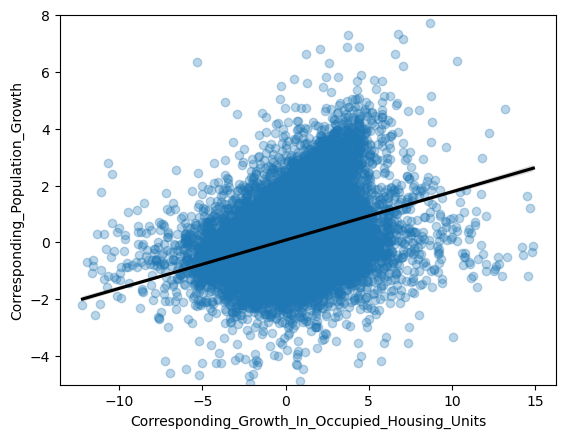

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.regplot(
    data=Housing_df,
    x="Corresponding_Growth_In_Occupied_Housing_Units",
    y="Corresponding_Population_Growth", 
    lowess=False,
    line_kws = {"color":"black"},
    scatter_kws={"alpha":0.3}
)

plt.ylim(-5, 8)

In [13]:
#Comparing transformations to see which is best


from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
def compare_model(X, y, name):
    model = LinearRegression()

    rmse = -cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="neg_root_mean_squared_error"
    ).mean()

    r2 = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="r2"
    ).mean()

    print(f"{name}")
    print(f"RMSE: {rmse:.5f}")
    print(f"R²: {r2:.5f}")
    print()




#1
X = Housing_df[["Corresponding_Growth_In_Occupied_Housing_Units"]]
y = Housing_df["Corresponding_Population_Growth"]
#y = Housing_df[""]
compare_model(X, y, "Linear")

#2
#Housing_df["log_Corr_Housing_Growth"] = np.log1p(Housing_df["Corresponding_Growth_In_Occupied_Housing_Units"])
#X=Housing_df[["log_Corr_Housing_Growth"]]
#compare_model(X, y, "Log")

#3
Housing_df["Corr_Housing_Growth_squared"] = (Housing_df["Corresponding_Growth_In_Occupied_Housing_Units"]**2)
X=Housing_df[["Corresponding_Growth_In_Occupied_Housing_Units", "Corr_Housing_Growth_squared"]]
compare_model(X, y, "Squared Quadratic")

#4
Housing_df["Corr_Housing_Growth_cubed"] = (Housing_df["Corresponding_Growth_In_Occupied_Housing_Units"]**3)
X = Housing_df[["Corresponding_Growth_In_Occupied_Housing_Units", "Corr_Housing_Growth_squared", "Corr_Housing_Growth_cubed"]]
compare_model(X, y, "Cubed Quadratic/Cubic")

#5
#Housing_df["sqrt_Corr_Housing_Growth"] = np.sqrt(Housing_df["Corresponding_Growth_In_Occupied_Housing_Units"])
#X = Housing_df[["sqrt_Corr_Housing_Growth"]]
#compare_model(X, y, "Square Root")

#6
#Housing_df["recip_Corr_Housing_Growth"] = (1 / Housing_df["Corresponding_Growth_In_Occupied_Housing_Units"])
#X = Housing_df[["recip_Corr_Housing_Growth"]]
#compare_model(X, y, "Reciprocal")


#Housing_df["PopGrowth_Dependency"] = (Housing_df["Pop_Growth_Pct"] * Housing_df["Dependency_Ratio"])
#X = Housing_df[["PopGrowth_Dependency"]]
#compare_model(X, y, "Interaction")


#For total population, a log relationship is best, it performs best in terms of the R2 & RMSE tests, and a linear log trendline fits the
#data very well

#For Median House Value, a log relationship is best, it's slightly worse than the reciprocal term in terms of the R2 & RMSE tests,
#But the linear log trendline is best at fitting the data

#For Median Rent, a reciprocal relationship is best, it only ranks 3rd in terms of the R2 & RMSE tests, but it does a far better job of
#fitting the data than either of those two

#For Households Per 1000, a linear specification fits the data very well

#For Median Household Income, a reciprocal relationship is best, in terms of R2 and RMSE tests, they were all very close, as the highest
#R2 was roughly 0.12, and the lowest at 0.11, but a reciprocal relationship did the best job of fitting the data, especially at the high
#end of the income distribution

#For Median Age, the best specification was linear, not in terms of R2 or RMSE, but it was good at mapping data

#For Foreign Born %, the best specification was log, in terms of R2 or RMSE, and it was slightly better at mapping data than any other one

#For total permits per 1000, as well as single, multifamily, and 5+ units, the linear specification works and is important
#because it won't work with many other specifications

#Homeownership Rate works well as a linear specification, not in terms of R2 or RMSE, but it maps out the relationship pretty well, though
#many of the others also did

#Employment Population Ratio works well as a linear specification because it maps out the relationship quite well.
#This was also the case with poverty rate, and the percent of white people in a county

#For the percent of black people in a county, a cubic relationship was best

#For Rent Burden, the linear term is best because it fits the relationship quite well

#For Population density, the log term is best because it fits the relationship quite well




#For The Specifications:
#Log: Total Population, Median House Value, Foreign Born %, and Population Density
#Linear: Total Permits, Single Family, Multifamily, 5+ units, Homeownership Rate, E/Pop Ratio, Poverty Rate, Median Age,
#White% in a county and Rent Burden
#Reciprocal: Median Rent, Median Household Income
#Cubic: Black% in a county

Linear
RMSE: 0.94425
R²: 0.10462

Squared Quadratic
RMSE: 0.94422
R²: 0.10470

Cubed Quadratic/Cubic
RMSE: 0.93591
R²: 0.12029



In [14]:
#Final Vars for Regression in the Order They Appear


Y = Housing_df.Corresponding_Population_Growth


X_Tot = Housing_df[
    [
    'Corresponding_Growth_In_Occupied_Housing_Units',
    'Total_Permits_per_1000',
    'Permits_x_Housing_Growth',
    'Permits_x_House_Value',
    'Homeownership_Rate',
    'Employment_Population_Ratio',
    'White_Pct',
    'Change_In_Foreign_Born_Share',
    'White_Pct_squared',
    'Rent_Burden_Over_30_Pct',
    'Median_House_Value',
    'Median_Age_Years',
    'log_Foreign_Born_Pct',
    'log_Population_Density',
    'recip_Median_Income',
    'Black_Pct',
    'Black_Pct_squared',
    'Black_Pct_cubed'
    ]
]




X_Sing = Housing_df[
    [
    'Corresponding_Growth_In_Occupied_Housing_Units',
    'Single_Family_Permits_per_1000',
    'Single_Permits_x_Housing_Growth',
    'Single_Permits_x_House_Value',
    'Homeownership_Rate',
    'Employment_Population_Ratio',
    'White_Pct',
    'Change_In_Foreign_Born_Share',
    'White_Pct_squared',
    'Rent_Burden_Over_30_Pct',
    'Median_House_Value',
    'Median_Age_Years',
    'log_Foreign_Born_Pct',
    'log_Population_Density',
    'recip_Median_Income',
    'Black_Pct_squared',
    'Black_Pct',
    'Black_Pct_cubed'
    ]
]




X_Multi = Housing_df[
    [
    'Corresponding_Growth_In_Occupied_Housing_Units',
    'Total_Multifamily_Permits_per_1000',
    'Multi_Permits_x_Housing_Growth',
    'Multi_Permits_x_House_Value',
    'Homeownership_Rate',
    'Employment_Population_Ratio',
    'White_Pct',
    'Change_In_Foreign_Born_Share',
    'White_Pct_squared',
    'Rent_Burden_Over_30_Pct',
    'Median_House_Value',
    'Median_Age_Years',
    'log_Foreign_Born_Pct',
    'log_Population_Density',
    'recip_Median_Income',
    'Black_Pct_squared',
    'Black_Pct',
    'Black_Pct_cubed'
    ]
]




X_5 = Housing_df[
    [
    'Corresponding_Growth_In_Occupied_Housing_Units',
    '5_or_More_Unit_Permits_per_1000',
    '5_Unit_Permits_x_Housing_Growth',
    '5_Unit_Permits_x_House_Value',
    'Homeownership_Rate',
    'Employment_Population_Ratio',
    'White_Pct',
    'Change_In_Foreign_Born_Share',
    'White_Pct_squared',
    'Rent_Burden_Over_30_Pct',
    'Median_House_Value',
    'Median_Age_Years',
    'log_Foreign_Born_Pct',
    'log_Population_Density',
    'recip_Median_Income',
    'Black_Pct_squared',
    'Black_Pct',
    'Black_Pct_cubed'
    ]
]

#This is the model that will fit for Y (Corresponding_Population_Growth)
#It has all the requisite transformations done, and is ready for a linear regression.

In [20]:
X_Tot.describe()

,Corresponding_Growth_In_Occupied_Housing_Units,Total_Permits_per_1000,Permits_x_Housing_Growth,Permits_x_House_Value,Homeownership_Rate,Employment_Population_Ratio,White_Pct,Change_In_Foreign_Born_Share,White_Pct_squared,Rent_Burden_Over_30_Pct,Median_House_Value,Median_Age_Years,log_Foreign_Born_Pct,log_Population_Density,recip_Median_Income,Black_Pct,Black_Pct_squared,Black_Pct_cubed
count,35904.000000,35904.000000,35904.000000,3.590400e+04,35904.000000,35904.000000,35904.000000,35904.000000,35904.000000,35904.000000,3.590400e+04,35904.000000,35904.000000,35904.000000,35904.000000,35904.000000,35904.000000,35904.000000
mean,0.427651,2.444890,3.018783,4.722574e+05,72.048808,54.798389,76.928138,0.041248,6313.137596,38.701268,1.463888e+05,40.641625,1.415807,3.999357,0.000022,9.185798,296.418908,13562.531879
std,1.921366,3.161651,11.669157,8.962296e+05,8.014870,8.099765,19.879893,0.557820,2630.171909,8.915662,9.237356e+04,5.085517,0.743698,1.549268,0.000006,14.561797,801.390402,50954.050230
min,-12.214829,0.000000,-131.143438,0.000000e+00,18.971460,10.965100,0.635450,-9.470765,0.403797,0.000000,2.600000e+04,21.400000,0.000000,0.036125,0.000006,0.000000,0.000000,0.000000
25%,-0.528625,0.490767,-0.208744,4.697615e+04,68.089403,49.467803,65.373253,-0.148836,4273.662142,32.998275,9.010000e+04,37.700000,0.843930,3.049723,0.000018,0.626315,0.392270,0.245685
50%,0.425441,1.467005,0.245256,1.829825e+05,73.259715,55.250345,84.122440,0.035276,7076.584912,39.391885,1.209000e+05,40.700000,1.294513,3.885136,0.000021,2.315525,5.361656,12.415049
75%,1.378361,3.124582,2.548095,5.161512e+05,77.513775,60.770498,92.887855,0.234080,8628.153607,44.995605,1.684000e+05,43.600000,1.897119,4.835216,0.000025,10.652013,113.465370,1208.634548
max,14.904863,44.947240,330.799534,2.150575e+07,96.985820,90.103810,100.000000,8.821110,10000.000000,70.000000,1.441300e+06,68.300000,4.093134,11.207400,0.000053,87.412280,7640.906695,667909.075460


In [21]:
X_Tot_ols = sm.add_constant(X_Tot)
#This line is essential for the Y-Intercept

model = sm.OLS(Y, X_Tot_ols).fit()

print(model.summary())

model.params



#The interpretations behind the coefficients are shown below

#Corresponding Growth Rate In Occupied Housing Units: for each percent that the corresponding growth in occupied housing units increases
#corresponding population growth (the dependent variable) increases by 0.0535%. The standard deviation is 1.92 (or 1.92%),
#so a 1 standard deviation increase in the variable corresponds to population growth increasing by 0.103 percentage points (1.92*0.0535).
#This means increasing the number of housing units has a positive effect on population growth. It's likely that the effect would be larger
#but many variables are likely to be absorbing the effect it has on population growth.

#Total Permits per 1000 has a coefficient of 0.1708, meaning that for each additional permit per 1,000, population growth increases by
#0.1708%. The standard deviation is 3.16 (or 3.16 additional permits per 1,000), so a one standard deviation increase in permitting rate 
#corresponds with a 0.54% increase in population growth (3.161651*0.1708). This means an increase in the number of house permits has a very
#strong effect on population growth

#Homeownership rate has a coefficient of 0.0219, meaning that for each percent increase in homeownership rate, population growth increases
#by 0.0219%. The standard deviation is 8.01 (or 8.01%) so a one standard deviation increase in homeownership rate corresponds with a 0.176%
#increase in population growth (8.014870*0.0219). This means an increase in homeownership rate has a relatively strong effect on population
#growth

#Employment population ratio has a coefficient of 0.0060, meaning that for each percent increase in E/Pop, population growth increases by
#0.006%. The standard deviation is 8.10 (or 8.10%), so a one standard deviation increase in E/Pop corresponds with a 0.0486% increase 
#in population growth (8.099765*0.0060). This means a better labor market has a slightly positive effect on population growth.

#The coefficient for rent burden is not statistically significant, so it can't be judged to have an effect on the dependent variable
#based on this model.

#The coefficient for median house value is 1.853e-06, meaning that for each dollar increase in median house value, population growth 
#percentage increases by 0.000001853%. While that number is extremely small, one standard deviation for the variable is very large at
#9.237356e+04 (which is equivalent to $92,373.56). Therefore, a one standard deviation increase in house value corresponds to a 0.171%
#increase in population growth. While this points to median house value having a positive effect on population growth, it's worth noting
#that increased construction (which results from increased permitting) tends to lead to decreased house prices, so there may be a confounder
#like crime rate, or public service quality which pushes the price of housing up, but also makes the place more desirable.

#The coefficient for median age (yrs) is -0.0448, meaning for every year that median age increases, population growth decreases by 0.0448%.
#The standard deviation is 5.09 (or 5.09 years), so a one standard deviation increase in age corresponds with a 0.228% decrease in population
#growth. This means older counties tend to have lower population growth figures, likely because older people are more likely to live in rural
#counties, but also because older counties are likely to invest less in high quality public schools.

#The coefficient for log_foreign_born_percent is 0.1523, meaning that a one percent relative increase in foreign born population in a county
#corresponds to a 0.001523% increase in population growth (in absolute terms). In the context of this variable, the mean for the logged value
#is 1.415807 and the standard deviation is 0.743698. In order to convert those numbers to percent terms, you need to use exponentiation.
#The math is shown below:
#e^(1.415807+0.743698) = 8.67. e^1.415807 = 4.12. That 4.55% increase in foreign born population as a share of a county's population
#is a 110.37% relative increase. To interpret the coefficient, the final value is 0.1523*ln(1 + (110.37/100)) = 0.1132%. In simpler terms
#supposing a county has 100,000 people with 4,120 immigrants, an increase to 8,670 corresponds to population growth being 0.1132% higher.
#Therefore, if their population growth is normally 1.5%, it would then become 1.61%.

#The explanation for the linear-log coefficient interpretation is shown below
#https://library.virginia.edu/data/articles/interpreting-log-transformations-in-a-linear-model


#The coefficient for log_population_density is 0.0635, meaning that a one percent relative increase in population density for a county
#corresponds to a 0.0635% increase in population growth (in absolute terms). In the context of this variable, the mean for the logged value
#is 3.999357 and the standard deviation is 1.549268. In order to convert this to percentage terms, you need exponentiation.
#The math is shown below:
#e^(3.999357+1.549268) = 256.88. e^3.999357 = 54.56. That increase in population density is a 370.80% relative increase. To interpret this
#the final value is 0.0635*ln(1 + (370.8/100)) = 0.0635 * 1.549 = 0.0984% absolute increase in population growth (so 1% to 1.0984%).

#In the case of both logged specifications, the actual effect, even as a result of substantial changes to the independent variable are quite
#small, and this may be a result of other variables absorbing the effect they have on population growth. Regardless, not only do the
#regression models signal small effects, but the gradient boosting models also find these two variables to have
#relatively low feature importance, while population density is quite important in the SHAP model, unlike foreign born share, which is not
#considered important.


#When it comes to the percent of people in a county who are black, the linear coefficient is not significant, but the quadratic and cubic
#terms are significant. The mean for the percent of black people in a county is 9.185798%, and the standard deviation is 14.561797%.
#For simplicity's sake, using those figures (and making the linear coefficient zero because it isn't significant), an increase in one
#standard deviation has the effect shown below based on this equation (-0.0005x^2 + 0.000003461*x^3):
#(-0.0005*(23.748^2) + 0.000003461*(23.748^3)) = -0.282 + 0.0464 = -0.236
#(-0.0005*(9.185798)^2 + 0.000003461*(9.185798)^3) = -0.0422 + 0.00268 = -0.0395
#In this case, a one standard deviation increase corresponds to a (-0.236 - (-0.0395)) = -0.196, or a 0.196% decrease in population growth.
#This means that increased racial diversity (especially counties with more black people) has some level of a negative effect on
#population growth, which has been observed quite often throughout the 20th century.

#When it comes to the percent of people in a county who are white, the linear coefficient is 0.0166,
#and the quadratic coefficient is -0.0001. The mean and standard deviation for the percent of white people in a county is:
#(76.928138% and 19.879893% respectively). A one standard deviation increase in the white population (as a percent) has the effect as shown
#below based on this equation (0.0166*x - 0.0001*x^2):
#(0.0166*96.808031 - 0.0001*(96.808031^2)) = 1.607 - 0.937 = 0.670
#(0.0166*76.928138 - 0.0001*(76.928138^2)) = 1.277 - 0.592 = 0.685
#In this case, a one standard deviation increase corresponds to a (0.670 - 0.685) = -0.015 or a 0.015% decrease in population growth.
#In this case, a very homogenous county is negatively correlated with population growth, which may have to do with many rural counties being
#very homogenous, since rural counties have generally had lower population growth rates.


#The coefficient for the reciprocal of median income is 1.633e+04, with a mean of 0.000022 and a standard deviation of 0.000006.
#When inverted, the mean is equal to $45,454.54. As the reciprocal increases, then the value decreases, so a one standard deviation increase
#in median income comes from subtracting the standard deviation from the mean. In this case, that equals 1/(0.000022 - 0.000006) = 1/0.000016
#which equals $62,500. The change from the reciprocal term is 16,330(0.000016 - 0.000022) = -0.09798. This means that the increase in median
#income corresponds to a decrease of 0.09798% in population growth. This may be because high income counties are more expensive on average,
#which is the opposite effect of the house value variable.


#For the permit*housing growth interaction variable, the coefficient was 0.0067. Going back to the original variables, the mean and SD
#for permits was 2.444890 and 3.161651 while the mean and SD for growth in housing units was 0.427651 and 1.921366. Assuming the two values
#are at the mean, the value is 2.444890*0.427651 = 1.04556. If you increase both by one standard deviation, the value is:
#5.606541*2.348366 = 13.166
#If you only increase the permits by one standard deviation, the value is 5.606541*0.427651 = 2.398
#If you only increase the growth in units by one standard deviation, the value is 2.444890*2.348366 = 5.741
#All of these values need to be multiplied by the coefficient of 0.0067. In the event where both variables are at the sample means,
#the contribution is 1.04556*0.0067 = 0.00701% absolute population growth relative to both figures being equal to zero
#In the event where both values are one SD higher, the contribution is 13.1662*0.0067 = 0.0882% absolute population growth increase relative
#to both figures equaling zero.
#When only permit rate is one SD higher, the contribution is 2.398*0.0067 = 0.0161% absolute population growth increase relative to the
#figures equaling zero
#When only the growth in housing units is one SD higher, the contribution is 5.741*0.0067 = 0.0385% increased absolute population growth
#relative to the figures equaling zero
#Lookiing at the mean and SD for the value of the interaction variable in total, the mean was 3.018783, and the SD was 11.669157
#An one standard deviation increase corresponds to a population growth increase of 11.669157*0.0067 = 0.0782% increase in population growth.

#It's important to note that while the permitting figure can't be negative, the growth in housing units can be negative, so if it's negative
#then the interaction term's contribution to population growth rate can be negative


#For the permit*house value interaction variable, the coefficient was -2.34e-07. Going back to the original variables, the mean and SD
#for permits was 2.444890 and 3.161651 while the mean and SD for house value was 1.463888e+05 and 9.237356e+04 ($146,388.80 and $92,373.56
#respectively). Assuming the two values are at the mean, the value is 2.444890*(1.463888e+05) = 357,904.51. If you increase both by one
#standard deviation, the value is 5.606541*238,762.36 = 1,338,630.96
#If you only increase the permits by one standard deviation, the value is 5.606541*1.463888e+05 = 820,734.81
#If you only increase the housing price by one standard deviation, the value is 2.444890*238,762.36 = 583,747.71
#All of these values need to be multiplied by the coefficient of -2.34e-07. In the event where both variables are at the sample means,
#the contribution is 357,904.51*(-2.34e-07) = 0.0837% decrease in absolute population growth relative to both figures being equal to zero.
#In the event where both values are one SD higher, the contribution is 1,338,630.96*(-2.34e-07) = 0.313% absolute decrease in population
#growth relative to both figures equaling zero.
#When only permit rate is one SD higher, the contribution is 820,734.81*(-2.34e-07) = 0.192% absolute decrease in population growth relative
#to the figures equaling zero
#When only the growth in housing units is one SD higher, the contribution is 583,747.71*(-2.34e-07) = 0.137% absolute decrease in population
#growth relative to the figures equaling zero


#To contextualize the permit figure, and the other two variables in the interaction term:
#Assuming the median house value and permit rates are equal to the mean, and the growth in housing units is equal to -0.5
#The collective contribution to the model will be
#0.1708*2.444890 + 1.844e-06*(1.463888e+05) + 0.0535*(-0.5) + 0.0067*(2.444890*(-0.5)) - 2.34e-07*(2.444890*1.463888e+05) =
#0.418 + 0.270 - 0.02675 - 0.00819 - 0.0837 = 0.569 or a 0.569% increase as opposed to all of those values equaling zero. Rather than the two
#interaction terms causing the cumulative effect of the variables to be negative, they simply moderate the effect of permitting on
#population growth.


#The effect of permitting on population growth is marginally larger for each multifamily permit, and slightly smaller for 5 unit permits,
#in spite of the fact that each multifamily permit enables at least 2 units to be built. This means the model is likely underestimating the
#effect of multifamily permits.

                                   OLS Regression Results                                  
Dep. Variable:     Corresponding_Population_Growth   R-squared:                       0.477
Model:                                         OLS   Adj. R-squared:                  0.477
Method:                              Least Squares   F-statistic:                     1822.
Date:                             Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                                     00:40:29   Log-Likelihood:                -39258.
No. Observations:                            35904   AIC:                         7.855e+04
Df Residuals:                                35885   BIC:                         7.872e+04
Df Model:                                       18                                         
Covariance Type:                         nonrobust                                         
                                                     coef    std err          t 

const                                            -1.705063e+00
Corresponding_Growth_In_Occupied_Housing_Units    5.348555e-02
Total_Permits_per_1000                            1.707792e-01
Permits_x_Housing_Growth                          6.650541e-03
Permits_x_House_Value                            -2.335623e-07
Homeownership_Rate                                2.186924e-02
Employment_Population_Ratio                       5.744608e-03
White_Pct                                         1.636969e-02
Change_In_Foreign_Born_Share                      3.483456e-02
White_Pct_squared                                -1.336405e-04
Rent_Burden_Over_30_Pct                           6.981177e-05
Median_House_Value                                1.843785e-06
Median_Age_Years                                 -4.487320e-02
log_Foreign_Born_Pct                              1.561794e-01
log_Population_Density                            6.263894e-02
recip_Median_Income                               1.625

In [22]:
X_Sing_ols = sm.add_constant(X_Sing)
#This line is essential for the Y-Intercept

model_Sing = sm.OLS(Y, X_Sing_ols).fit()

print(model_Sing.summary())


model_Sing.params

                                   OLS Regression Results                                  
Dep. Variable:     Corresponding_Population_Growth   R-squared:                       0.479
Model:                                         OLS   Adj. R-squared:                  0.479
Method:                              Least Squares   F-statistic:                     1835.
Date:                             Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                                     00:40:29   Log-Likelihood:                -39195.
No. Observations:                            35904   AIC:                         7.843e+04
Df Residuals:                                35885   BIC:                         7.859e+04
Df Model:                                       18                                         
Covariance Type:                         nonrobust                                         
                                                     coef    std err          t 

const                                            -1.441055e+00
Corresponding_Growth_In_Occupied_Housing_Units    5.988230e-02
Single_Family_Permits_per_1000                    1.920946e-01
Single_Permits_x_Housing_Growth                   4.372957e-03
Single_Permits_x_House_Value                     -1.595712e-07
Homeownership_Rate                                1.692899e-02
Employment_Population_Ratio                       8.245240e-03
White_Pct                                         1.690552e-02
Change_In_Foreign_Born_Share                      3.915429e-02
White_Pct_squared                                -1.344654e-04
Rent_Burden_Over_30_Pct                           2.363334e-04
Median_House_Value                                1.397408e-06
Median_Age_Years                                 -4.711853e-02
log_Foreign_Born_Pct                              1.647693e-01
log_Population_Density                            7.511518e-02
recip_Median_Income                               1.701

In [23]:
X_Multi_ols = sm.add_constant(X_Multi)
#This line is essential for the Y-Intercept

model_Multi = sm.OLS(Y, X_Multi_ols).fit()

print(model_Multi.summary())


model_Multi.params

                                   OLS Regression Results                                  
Dep. Variable:     Corresponding_Population_Growth   R-squared:                       0.366
Model:                                         OLS   Adj. R-squared:                  0.366
Method:                              Least Squares   F-statistic:                     1153.
Date:                             Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                                     00:40:30   Log-Likelihood:                -42716.
No. Observations:                            35904   AIC:                         8.547e+04
Df Residuals:                                35885   BIC:                         8.563e+04
Df Model:                                       18                                         
Covariance Type:                         nonrobust                                         
                                                     coef    std err          t 

const                                            -1.932280e+00
Corresponding_Growth_In_Occupied_Housing_Units    9.543564e-02
Total_Multifamily_Permits_per_1000                1.963998e-01
Multi_Permits_x_Housing_Growth                    4.244640e-02
Multi_Permits_x_House_Value                      -7.141673e-07
Homeownership_Rate                                2.531075e-02
Employment_Population_Ratio                       6.051018e-03
White_Pct                                         1.776654e-02
Change_In_Foreign_Born_Share                      3.579964e-02
White_Pct_squared                                -1.431295e-04
Rent_Burden_Over_30_Pct                           3.179661e-03
Median_House_Value                                2.484961e-06
Median_Age_Years                                 -4.130537e-02
log_Foreign_Born_Pct                              1.801237e-01
log_Population_Density                            6.157223e-02
recip_Median_Income                               4.708

In [24]:
X_5_ols = sm.add_constant(X_5)
#This line is essential for the Y-Intercept

model_5 = sm.OLS(Y, X_5_ols).fit()

print(model_5.summary())


model_5.params

                                   OLS Regression Results                                  
Dep. Variable:     Corresponding_Population_Growth   R-squared:                       0.362
Model:                                         OLS   Adj. R-squared:                  0.362
Method:                              Least Squares   F-statistic:                     1133.
Date:                             Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                                     00:40:30   Log-Likelihood:                -42830.
No. Observations:                            35904   AIC:                         8.570e+04
Df Residuals:                                35885   BIC:                         8.586e+04
Df Model:                                       18                                         
Covariance Type:                         nonrobust                                         
                                                     coef    std err          t 

const                                            -1.871292e+00
Corresponding_Growth_In_Occupied_Housing_Units    9.940540e-02
5_or_More_Unit_Permits_per_1000                   1.888759e-01
5_Unit_Permits_x_Housing_Growth                   4.767893e-02
5_Unit_Permits_x_House_Value                     -7.339035e-07
Homeownership_Rate                                2.468637e-02
Employment_Population_Ratio                       6.401172e-03
White_Pct                                         1.796290e-02
Change_In_Foreign_Born_Share                      3.544219e-02
White_Pct_squared                                -1.437076e-04
Rent_Burden_Over_30_Pct                           3.296293e-03
Median_House_Value                                2.416230e-06
Median_Age_Years                                 -4.180066e-02
log_Foreign_Born_Pct                              1.812898e-01
log_Population_Density                            6.111759e-02
recip_Median_Income                               4.321

In [25]:
#Linear Regression Portion Using scikit-learn

In [26]:
from sklearn.model_selection import train_test_split

In [27]:
X_train, X_test, Y_train, Y_test = train_test_split(X_Tot, Y, test_size=0.2, random_state = 41)

In [28]:
X_train.shape, Y_train.shape
#Trained Data

((28723, 18), (28723,))

In [29]:
X_test.shape, Y_test.shape
#Data For Testing

((7181, 18), (7181,))

In [30]:
from sklearn import linear_model
from sklearn.metrics import root_mean_squared_error, mean_squared_error, r2_score

#Linear regression model imports

In [31]:
model = linear_model.LinearRegression()
#Linear regression

In [32]:
model.fit(X_train, Y_train)
#Building the training model

LinearRegression()

In [33]:
Y_pred = model.predict(X_test)
#Applies trained model to make a prediction on the test set

In [34]:
coefficients = pd.DataFrame({
    'Variable': X_Tot.columns,
    'Coefficient': model.coef_
})

print(coefficients)

print('Coefficients:', model.coef_)
print('Intercept:', model.intercept_)

Y_train_pred = model.predict(X_train)

print('Coefficient of determination (R^2) for training data: %.4f' % r2_score(Y_train, Y_train_pred))
#R^2 based on the training data, essentially the values of Y based on the training data, vs the predictions of the training data using X_train
print('Root mean squared error (RMSE) for training data: %.4f'
      % root_mean_squared_error(Y_train, Y_train_pred))
#Root mean squared error also based on the training data

print('Coefficient of determination (R^2) for test data: %.4f'
      % r2_score(Y_test, Y_pred))
#R^2 based on the test data, essentially the values of Y based on the test data, vs the predictions of the test data using X_test
print('Root mean squared error (RMSE) for test data: %.4f'
      % root_mean_squared_error(Y_test, Y_pred))


                                          Variable   Coefficient
0   Corresponding_Growth_In_Occupied_Housing_Units  4.892410e-02
1                           Total_Permits_per_1000  1.643751e-01
2                         Permits_x_Housing_Growth  6.442904e-03
3                            Permits_x_House_Value -2.179954e-07
4                               Homeownership_Rate  1.952442e-02
5                      Employment_Population_Ratio  6.612415e-04
6                                        White_Pct  1.443543e-02
7                     Change_In_Foreign_Born_Share  4.003761e-02
8                                White_Pct_squared -1.152663e-04
9                          Rent_Burden_Over_30_Pct  1.563322e-03
10                              Median_House_Value  1.403469e-06
11                                Median_Age_Years -4.543151e-02
12                            log_Foreign_Born_Pct  1.513761e-01
13                          log_Population_Density  5.458141e-02
14                       

In [35]:
#When comparing the coefficients from the machine learning model to the baseline model, these values compare quite favorably to the
#OLS model that didn't use machine learning

#0   Corresponding_Growth_In_Occupied_Housing_Units  4.892410e-02 good
#1                           Total_Permits_per_1000  1.643751e-01 good
#2                         Permits_x_Housing_Growth  6.442904e-03 good
#3                            Permits_x_House_Value -2.179954e-07 good
#4                               Homeownership_Rate  1.952442e-02 good
#5                      Employment_Population_Ratio  6.612415e-04 decent
#6                                        White_Pct  1.443543e-02 good
#7                     Change_In_Foreign_Born_Share  4.003761e-02 good
#8                                White_Pct_squared -1.152663e-04 good
#9                          Rent_Burden_Over_30_Pct  1.563322e-03 not significant
#10                              Median_House_Value  1.403469e-06 bad
#11                                Median_Age_Years -4.543151e-02 good
#12                            log_Foreign_Born_Pct  1.513761e-01 good
#13                          log_Population_Density  5.458141e-02 decent
#14                             recip_Median_Income -1.176475e-07 finds the opposite relationship
#15                                       Black_Pct  1.613019e-03 not significant
#16                               Black_Pct_squared -4.214411e-04 good
#17                                 Black_Pct_cubed  3.389853e-06 good

#With the exception of the reciprocal of median income, the ML model returned very similar coefficient values for each of the variables
#With the exception of the median house value coefficient, every one was within 20% of the coefficient from the non-ML model, and most
#were within 10%

In [36]:
import seaborn as sns

In [37]:
Y_test

5186    -2.103628
2657     0.473852
23376    0.024726
42098   -0.191585
20349    0.218298
           ...   
9323     0.375211
28680   -0.149782
9761    -0.208215
4545     0.296945
2451    -0.666740
Name: Corresponding_Population_Growth, Length: 7181, dtype: float64

In [38]:
import numpy as np
np.array(Y_test)

array([-2.10362841,  0.47385224,  0.02472555, ..., -0.20821503,
        0.2969446 , -0.66673953])

In [39]:
Y_pred
np.array(Y_pred)

array([ 0.78791379,  0.95231751,  0.32786988, ..., -0.34767081,
       -0.29685258, -0.34669286])

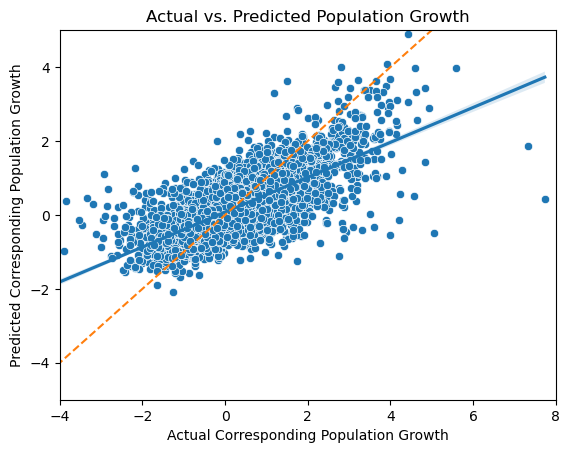

In [40]:
sns.scatterplot(x=Y_test, y=Y_pred)
sns.regplot(x=Y_test, y=Y_pred, scatter=False)

plt.xlim(-4, 8)
plt.ylim(-5, 5)
plt.plot([-10, 10], [-10, 10], linestyle='--')
plt.xlabel("Actual Corresponding Population Growth")
plt.ylabel("Predicted Corresponding Population Growth")
plt.title("Actual vs. Predicted Population Growth")
plt.show()

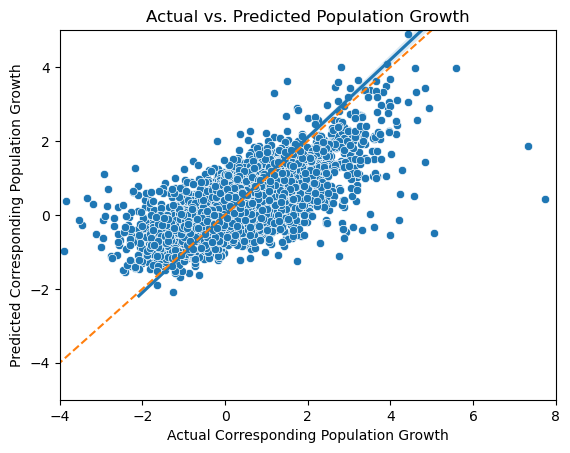

In [41]:
sns.scatterplot(x=Y_test, y=Y_pred)
sns.regplot(x=Y_pred, y=Y_test, scatter=False)

plt.xlim(-4, 8)
plt.ylim(-5, 5)
plt.plot([-10, 10], [-10, 10], linestyle='--')
plt.xlabel("Actual Corresponding Population Growth")
plt.ylabel("Predicted Corresponding Population Growth")
plt.title("Actual vs. Predicted Population Growth")
plt.show()

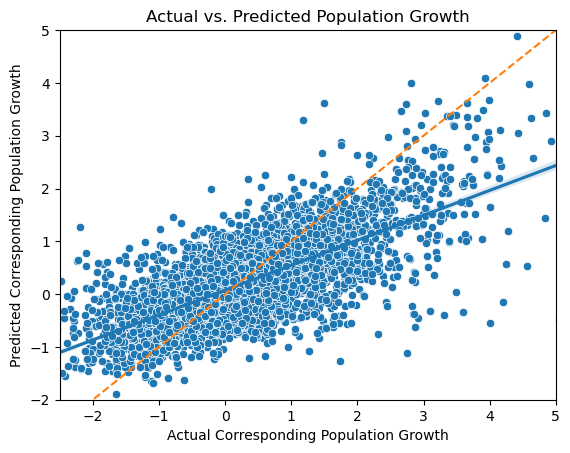

In [42]:
sns.scatterplot(x=Y_test, y=Y_pred)
sns.regplot(x=Y_test, y=Y_pred, scatter=False)

plt.xlim(-2.5, 5)
plt.ylim(-2, 5)
plt.plot([-10, 10], [-10, 10], linestyle='--')
plt.xlabel("Actual Corresponding Population Growth")
plt.ylabel("Predicted Corresponding Population Growth")
plt.title("Actual vs. Predicted Population Growth")
plt.show()

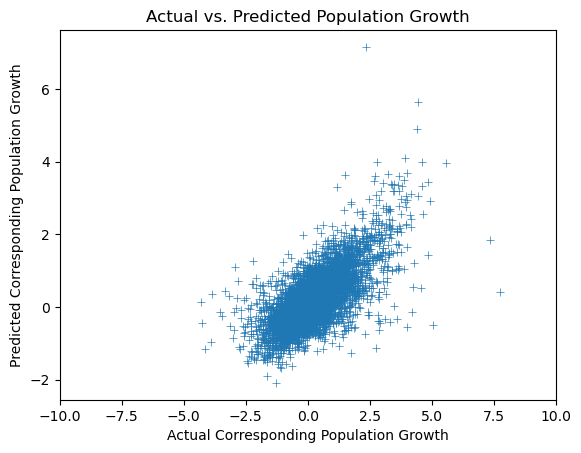

In [43]:
sns.scatterplot(x=Y_test, y=Y_pred, marker="+")

plt.xlim(-10, 10)
plt.xlabel("Actual Corresponding Population Growth")
plt.ylabel("Predicted Corresponding Population Growth")
plt.title("Actual vs. Predicted Population Growth")
plt.show()

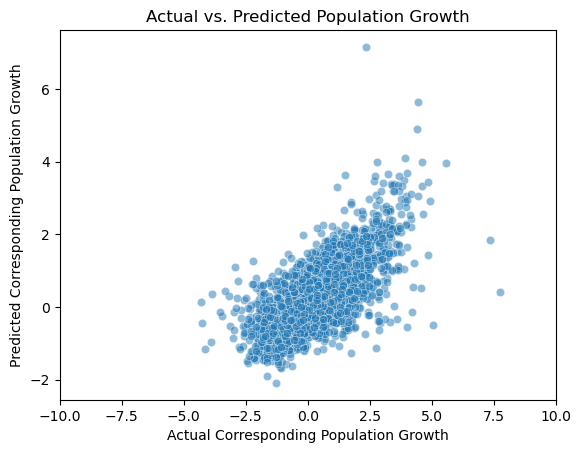

In [44]:
sns.scatterplot(x=Y_test, y=Y_pred, alpha=0.5)

plt.xlim(-10, 10)
plt.xlabel("Actual Corresponding Population Growth")
plt.ylabel("Predicted Corresponding Population Growth")
plt.title("Actual vs. Predicted Population Growth")
plt.show()

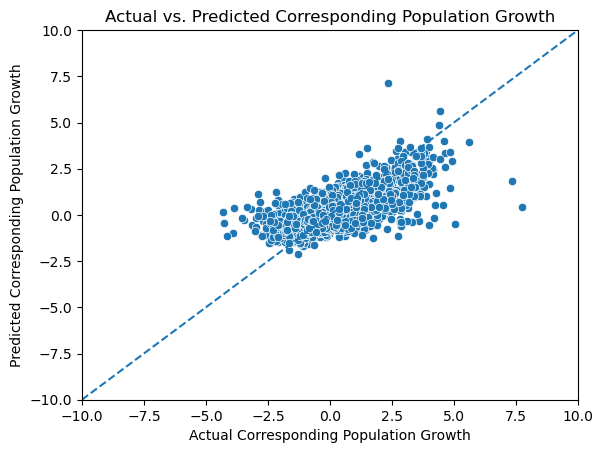

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(x=Y_test, y=Y_pred)

plt.plot(
    [-10, 10],
    [-10, 10],
    linestyle='--'
)

plt.xlim(-10, 10)
plt.ylim(-10, 10)

plt.xlabel("Actual Corresponding Population Growth")
plt.ylabel("Predicted Corresponding Population Growth")
plt.title("Actual vs. Predicted Corresponding Population Growth")
plt.show()

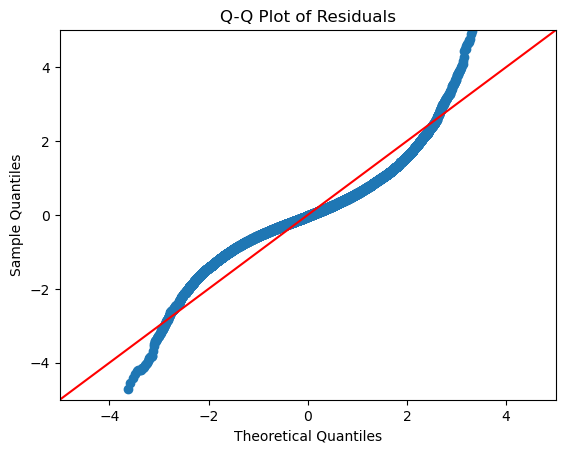

In [50]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Calculate residuals from the fitted scikit-learn model
residuals = Y_train - model.predict(X_train)

sm.qqplot(residuals, line='45')
plt.title("Q-Q Plot of Residuals")
plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()